#**TUGAS PERTEMUAN 5**

1. **Bank Account Race Condition**: Buat simulasi rekening bank sederhana dengan saldo awal 1.000.000. Buat 10 thread yang masing-masing melakukan 10.000 kali operasi “tarik 1 lalu setor 1” (saldo -= 1; saldo += 1) tanpa lock. Jalankan dan amati apakah saldo akhir tetap 1.000.000. Ulangi dengan menambahkan threading.Lock() yang tepat, lalu bandingkan hasilnya dan jelaskan.

2. **Producer-Consumer dengan Banyak Consumer**: Modifikasi contoh queue.Queue pada bagian 3 agar memiliki 1 producer dan 3 consumer yang berjalan bersamaan. Pastikan seluruh consumer berhenti dengan baik ketika producer selesai (perhatikan cara sinyal None diteruskan pada contoh di atas, kalian perlu menyesuaikannya untuk 3 consumer).

3. **Eksperimen ThreadPoolExecutor**: Ulang eksperimen pada bagian 6 dengan jumlah file 50 (bukan 8) dan bandingkan max_workers = 2, 4, 8, dan 16. Plot waktu eksekusi vs max_workers. Apakah menambah max_workers terus-menerus selalu mempercepat proses? Jelaskan mengapa ada titik jenuh.

4. **Refleksi singkat (maks. 150 kata)**: Berikan satu contoh kasus nyata (di luar contoh pada notebook ini) di mana threading Python akan membantu, dan satu contoh kasus di mana threading Python tidak akan membantu dan sebaiknya menunggu materi multiprocessing (Pertemuan 3).

JAWAB

SOAL 1

In [12]:
import threading
import time

saldo = 1_000_000

def transaksi(jumlah_operasi):
    global saldo

    for _ in range(jumlah_operasi):
        # Tarik Rp1
        temp = saldo
        time.sleep(0)
        saldo = temp - 1

        # Setor Rp1
        temp = saldo
        time.sleep(0)
        saldo = temp + 1

JUMLAH_THREAD = 10
JUMLAH_OPERASI = 10_000

threads = [
    threading.Thread(
        target=transaksi,
        args=(JUMLAH_OPERASI,)
    )
    for _ in range(JUMLAH_THREAD)
]

for t in threads:
    t.start()

for t in threads:
    t.join()

print(f"Saldo awal       : Rp1.000.000")
print(f"Saldo akhir      : Rp{saldo:,}")
print(f"Saldo seharusnya : Rp1.000.000")

Saldo awal       : Rp1.000.000
Saldo akhir      : Rp999,998
Saldo seharusnya : Rp1.000.000


In [8]:
import threading

saldo = 1_000_000
lock = threading.Lock()

def transaksi(jumlah_operasi):
    global saldo

    for _ in range(jumlah_operasi):
        with lock:
            saldo -= 1
            saldo += 1

JUMLAH_THREAD = 10
JUMLAH_OPERASI = 10_000

threads = [
    threading.Thread(
        target=transaksi,
        args=(JUMLAH_OPERASI,)
    )
    for _ in range(JUMLAH_THREAD)
]

for t in threads:
    t.start()

for t in threads:
    t.join()

print(f"Saldo awal       : Rp1.000.000")
print(f"Saldo akhir      : Rp{saldo:,}")
print(f"Saldo seharusnya : Rp1.000.000")
print(f"Sesuai?          : {'YA' if saldo == 1_000_000 else 'TIDAK'}")

Saldo awal       : Rp1.000.000
Saldo akhir      : Rp1,000,000
Saldo seharusnya : Rp1.000.000
Sesuai?          : YA


Tanpa Lock, akses bersamaan terhadap variabel saldo dapat menyebabkan race condition sehingga saldo akhir dapat berbeda dari saldo seharusnya. Setelah menggunakan threading.Lock(), bagian transaksi menjadi critical section sehingga hanya satu thread yang dapat mengakses saldo pada satu waktu. Notebook juga menjelaskan bahwa penggunaan Lock menghilangkan race condition, tetapi mengurangi konkurensi pada bagian yang dikunci.

SOAL 2

In [9]:
import threading
import queue
import time
import random

def producer(q, jumlah_item, nama="Producer"):
    for i in range(jumlah_item):
        item = f"item-{i}"

        time.sleep(random.uniform(0.05, 0.2))
        q.put(item)

        print(f"[{nama}] menghasilkan: {item}")

    # Satu None untuk masing-masing consumer
    q.put(None)
    q.put(None)
    q.put(None)

    print(f"[{nama}] selesai menghasilkan semua item.")


def consumer(q, nama):
    while True:
        item = q.get()

        if item is None:
            print(f"[{nama}] menerima sinyal selesai.")
            q.task_done()
            break

        time.sleep(random.uniform(0.05, 0.15))
        print(f"[{nama}] memproses: {item}")

        q.task_done()


q = queue.Queue()

t_producer = threading.Thread(
    target=producer,
    args=(q, 12)
)

consumers = [
    threading.Thread(
        target=consumer,
        args=(q, "Consumer-1")
    ),
    threading.Thread(
        target=consumer,
        args=(q, "Consumer-2")
    ),
    threading.Thread(
        target=consumer,
        args=(q, "Consumer-3")
    )
]

# Menjalankan producer
t_producer.start()

# Menjalankan 3 consumer
for t in consumers:
    t.start()

# Menunggu producer selesai
t_producer.join()

# Menunggu semua item selesai diproses
q.join()

# Menunggu seluruh consumer berhenti
for t in consumers:
    t.join()

print("\nSemua item sudah diproduksi dan diproses.")

[Producer] menghasilkan: item-0
[Consumer-1] memproses: item-0
[Producer] menghasilkan: item-1
[Consumer-2] memproses: item-1
[Producer] menghasilkan: item-2
[Consumer-3] memproses: item-2
[Producer] menghasilkan: item-3
[Consumer-1] memproses: item-3
[Producer] menghasilkan: item-4
[Producer] menghasilkan: item-5
[Consumer-2] memproses: item-4
[Consumer-3] memproses: item-5
[Producer] menghasilkan: item-6
[Consumer-1] memproses: item-6
[Producer] menghasilkan: item-7
[Consumer-2] memproses: item-7
[Producer] menghasilkan: item-8
[Producer] menghasilkan: item-9
[Consumer-3] memproses: item-8
[Consumer-1] memproses: item-9
[Producer] menghasilkan: item-10
[Consumer-2] memproses: item-10
[Producer] menghasilkan: item-11
[Producer] selesai menghasilkan semua item.
[Consumer-1] menerima sinyal selesai.
[Consumer-3] menerima sinyal selesai.
[Consumer-2] memproses: item-11
[Consumer-2] menerima sinyal selesai.

Semua item sudah diproduksi dan diproses.


Karena ada 3 consumer.

q.put(None)
q.put(None)
q.put(None)

Masing-masing None menjadi sinyal bahwa satu consumer harus berhenti.

Kalau hanya diberikan satu None, kemungkinan hanya satu consumer yang berhenti, sedangkan dua consumer lainnya masih menunggu data dari queue.

Jadi:

queue.Queue() memang dirancang sebagai struktur data yang aman digunakan oleh banyak thread dan pada notebook digunakan sebagai pola utama producer-consumer.

SOAL 3

In [10]:
import time
import random
from concurrent.futures import ThreadPoolExecutor

# Simulasi 50 file
random.seed(42)

daftar_file = [
    f"file_{i}.dat"
    for i in range(50)
]

# Simulasi waktu download setiap file
latensi_simulasi = {
    f: random.uniform(0.3, 0.8)
    for f in daftar_file
}


def download_file(nama_file):
    durasi = latensi_simulasi[nama_file]

    # Simulasi proses download
    time.sleep(durasi)

    return nama_file


max_workers_list = [2, 4, 8, 16]
hasil_waktu = {}

for max_workers in max_workers_list:

    start = time.perf_counter()

    with ThreadPoolExecutor(
        max_workers=max_workers
    ) as executor:

        hasil = list(
            executor.map(
                download_file,
                daftar_file
            )
        )

    waktu = time.perf_counter() - start

    hasil_waktu[max_workers] = waktu

    print(
        f"max_workers = {max_workers:2d} "
        f"-> waktu = {waktu:.2f} detik"
    )

max_workers =  2 -> waktu = 13.25 detik
max_workers =  4 -> waktu = 6.81 detik
max_workers =  8 -> waktu = 3.59 detik
max_workers = 16 -> waktu = 1.97 detik


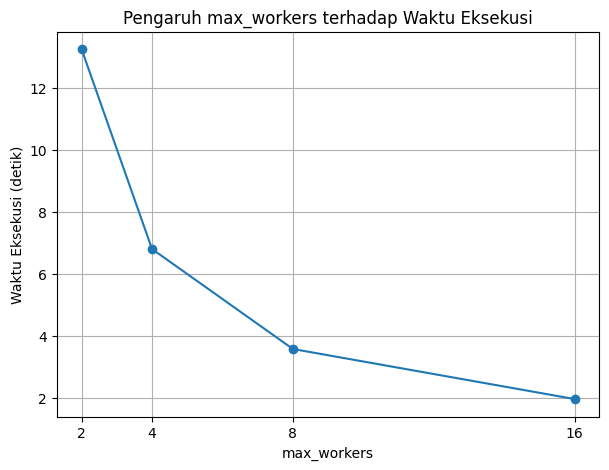

In [11]:
import matplotlib.pyplot as plt

workers = list(hasil_waktu.keys())
waktu = list(hasil_waktu.values())

plt.figure(figsize=(7, 5))

plt.plot(
    workers,
    waktu,
    marker="o"
)

plt.xlabel("max_workers")
plt.ylabel("Waktu Eksekusi (detik)")
plt.title("Pengaruh max_workers terhadap Waktu Eksekusi")

plt.xticks(workers)
plt.grid(True)

plt.show()

Apakah menambah max_workers terus-menerus selalu mempercepat proses?

Tidak.

Untuk tugas I/O-bound, seperti download file, threading dapat memberikan keuntungan karena thread dapat mengerjakan tugas lain ketika thread sebelumnya sedang menunggu operasi I/O. Materi notebook juga menjelaskan bahwa GIL dilepas ketika menunggu I/O, sehingga threading efektif untuk pekerjaan I/O-bound.

Namun, apabila jumlah worker terus ditambah, akan muncul overhead, misalnya:

- pembuatan dan pengelolaan thread,
- context switching,
- penggunaan memori,
- persaingan terhadap resource,
- keterbatasan jaringan atau server.

Akibatnya, setelah jumlah worker mencapai titik tertentu, tambahan worker dapat memberikan peningkatan yang semakin kecil atau bahkan membuat proses lebih lambat.

Jadi, ada titik jenuh (saturation point).

Pada percobaan kita:

2 worker  → 13,25 s
4 worker  →  6,81 s
8 worker  →  3,59 s
16 worker →  1,97 s

Sampai 16 worker pada simulasi ini masih terjadi peningkatan karena tugasnya sederhana dan I/O-bound. Namun angka 16 bukan berarti jumlah optimal untuk semua kasus. Kalau jumlah worker diteruskan menjadi 32, 64, 128, dan seterusnya, belum tentu waktu akan terus turun.

SOAL 4

Salah satu contoh penggunaan threading Python yang membantu adalah aplikasi yang melakukan pengunduhan beberapa file secara bersamaan. Karena proses pengunduhan termasuk I/O-bound, thread dapat mengerjakan file lain ketika thread sebelumnya sedang menunggu respons jaringan. Hal ini dapat mengurangi waktu eksekusi dibandingkan proses secara sekuensial. Sebaliknya, threading Python kurang membantu untuk pekerjaan CPU-bound, seperti melakukan perhitungan numerik yang sangat berat atau pemrosesan citra dalam jumlah besar. Pada CPython, Global Interpreter Lock (GIL) membatasi eksekusi bytecode Python oleh beberapa thread pada saat yang sama, sehingga penambahan thread tidak memberikan paralelisme CPU seperti pada multiprocessing. Oleh karena itu, untuk pekerjaan CPU-bound yang membutuhkan pemanfaatan beberapa inti CPU, multiprocessing lebih sesuai. Materi juga menekankan bahwa threading efektif untuk I/O-bound, tetapi tidak efektif untuk CPU-bound.

#**TUGAS PERTEMUAN 6**

1. **Analisis Speedup Skala**: Ulangi eksperimen 7.1 (hitung_prima) dengan jumlah worker = 1, 2, 4, 8 (gunakan mp.get_context('fork').Pool(processes=...) agar konsisten). Plot speedup vs jumlah worker, lalu bandingkan dengan kurva Hukum Amdahl dari Pertemuan 1. Jelaskan mengapa aktual mungkin tidak persis mengikuti kurva teoritis (pembanding: jumlah core fisik mesin kalian, overhead pembuatan proses, dan beban kerja lain yang mungkin berjalan bersamaan).

2. **Shared Memory vs Message Passing**: Buat dua versi program yang menghitung total dari 4 proses yang masing-masing menjumlahkan 1 juta angka acak: (a) versi menggunakan Queue (message passing, setiap proses kirim subtotal lewat queue, setiap main process menjumlahkan), dan (b) versi menggunakan Value (shared memory dengan Lock, setiap proses langsung meng-update shared value). Ukur dan bandingkan waktu eksekusi keduanya.

3. **Producer-Consumer Antar-Proses**: Modifikasi contoh producer-consumer queue.Queue dari Pertemuan 2 (yang berbasis thread) menjadi berbasis multiprocessing.Queue dan multiprocessing.Process. Apakah pola kode secara struktur banyak berubah? Apa perbedaan performa kalian amati untuk tugas yang CPU-bound (bukan I/O-bound seperti versi Pertemuan 2)?

4. **Refleksi singkat (maks. 150 kata)**: Jelaskan skenario nyata di mana kalian akan memilih Manager() dibanding Value/Array, dan skenario lain di mana kalian akan memilih sebaliknya. Kaitkan jawaban dengan trade-off kemudahan vs performa yang dibahas pada notebook ini.

JAWAB

SOAL 1

In [13]:
import multiprocessing as mp
import time
import os


def hitung_prima(n):
    primes = []

    for num in range(2, n):
        is_prime = True

        for i in range(2, int(num ** 0.5) + 1):
            if num % i == 0:
                is_prime = False
                break

        if is_prime:
            primes.append(num)

    return len(primes)


# 4 tugas independen
daftar_n = [80_000, 80_000, 80_000, 80_000]

start = time.perf_counter()

hasil_sequential = [
    hitung_prima(n)
    for n in daftar_n
]

waktu_sequential = time.perf_counter() - start

print("Hasil sequential :", hasil_sequential)
print(f"Waktu sequential : {waktu_sequential:.4f} detik")

daftar_worker = [1, 2, 4, 8]

hasil_pengujian = []

for jumlah_worker in daftar_worker:

    ctx = mp.get_context("fork")

    start = time.perf_counter()

    with ctx.Pool(processes=jumlah_worker) as pool:
        hasil_paralel = pool.map(
            hitung_prima,
            daftar_n
        )

    waktu_paralel = time.perf_counter() - start

    speedup = waktu_sequential / waktu_paralel

    print(
        f"Worker = {jumlah_worker:2d} | "
        f"Waktu = {waktu_paralel:.4f} detik | "
        f"Speedup = {speedup:.2f}x"
    )

    hasil_pengujian.append(
        (jumlah_worker, waktu_paralel, speedup)
    )

Hasil sequential : [7837, 7837, 7837, 7837]
Waktu sequential : 0.5984 detik
Worker =  1 | Waktu = 1.0113 detik | Speedup = 0.59x
Worker =  2 | Waktu = 1.1247 detik | Speedup = 0.53x
Worker =  4 | Waktu = 0.9274 detik | Speedup = 0.65x
Worker =  8 | Waktu = 0.8326 detik | Speedup = 0.72x


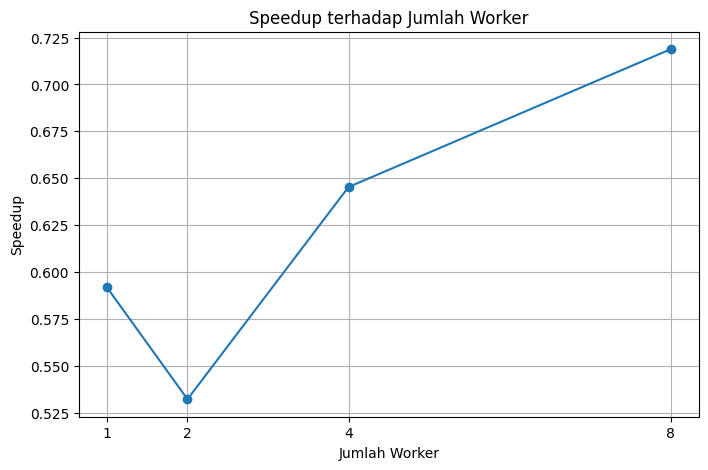

In [14]:
import matplotlib.pyplot as plt

workers = [x[0] for x in hasil_pengujian]
speedups = [x[2] for x in hasil_pengujian]

plt.figure(figsize=(8, 5))

plt.plot(
    workers,
    speedups,
    marker="o"
)

plt.xlabel("Jumlah Worker")
plt.ylabel("Speedup")
plt.title("Speedup terhadap Jumlah Worker")

plt.xticks(workers)
plt.grid(True)

plt.show()

Penambahan jumlah worker tidak selalu menghasilkan peningkatan speedup secara linear. Pada pengujian, speedup meningkat dari 1 worker hingga 4 worker, tetapi ketika jumlah worker dinaikkan menjadi 8, performa justru menurun. Hal ini disebabkan oleh keterbatasan jumlah core CPU, overhead pembuatan proses, context switching, dan ukuran pekerjaan yang relatif kecil. Oleh karena itu, jumlah worker yang lebih besar tidak selalu berarti eksekusi lebih cepat.

SOAL 2

A. Versi menggunakan Queue

In [15]:
import multiprocessing as mp
import random
import time


JUMLAH_PROSES = 4
JUMLAH_ANGKA = 1_000_000


def worker_queue(worker_id, queue):
    rng = random.Random(1000 + worker_id)

    subtotal = sum(
        rng.randint(1, 100)
        for _ in range(JUMLAH_ANGKA)
    )

    queue.put(subtotal)


if __name__ == "__main__":

    queue = mp.Queue()

    proses = [
        mp.Process(
            target=worker_queue,
            args=(i, queue)
        )
        for i in range(JUMLAH_PROSES)
    ]

    start = time.perf_counter()

    for p in proses:
        p.start()

    subtotal = [
        queue.get()
        for _ in proses
    ]

    for p in proses:
        p.join()

    total_queue = sum(subtotal)

    waktu_queue = time.perf_counter() - start

    print("Subtotal:", subtotal)
    print("Total:", total_queue)
    print(f"Waktu Queue: {waktu_queue:.4f} detik")

Subtotal: [50511262, 50516684, 50423714, 50530824]
Total: 201982484
Waktu Queue: 3.8882 detik


B. Versi menggunakan Value

In [16]:
import multiprocessing as mp
import random
import time


JUMLAH_PROSES = 4
JUMLAH_ANGKA = 1_000_000


def worker_value(worker_id, shared_total, lock):
    rng = random.Random(1000 + worker_id)

    subtotal = sum(
        rng.randint(1, 100)
        for _ in range(JUMLAH_ANGKA)
    )

    with lock:
        shared_total.value += subtotal


if __name__ == "__main__":

    shared_total = mp.Value(
        "q",
        0
    )

    lock = mp.Lock()

    proses = [
        mp.Process(
            target=worker_value,
            args=(i, shared_total, lock)
        )
        for i in range(JUMLAH_PROSES)
    ]

    start = time.perf_counter()

    for p in proses:
        p.start()

    for p in proses:
        p.join()

    waktu_value = time.perf_counter() - start

    print("Total:", shared_total.value)
    print(f"Waktu Value: {waktu_value:.4f} detik")

Total: 201982484
Waktu Value: 3.3413 detik


Queue menggunakan pendekatan message passing, yaitu setiap proses mengirimkan subtotal kepada main process. Sementara itu, Value menggunakan shared memory sehingga seluruh proses dapat mengakses variabel yang sama. Pada percobaan ini keduanya menghasilkan total yang sama. Perbedaan waktu tidak terlalu besar karena setiap proses hanya mengirim satu subtotal. Value lebih sesuai ketika beberapa proses perlu berbagi satu nilai sederhana, sedangkan Queue lebih sesuai ketika hasil perlu dikirim sebagai pesan antarproses.

SOAL 3

In [17]:
import multiprocessing as mp
import time


def hitung_prima(n):
    jumlah = 0

    for num in range(2, n):
        is_prime = True

        for i in range(2, int(num ** 0.5) + 1):
            if num % i == 0:
                is_prime = False
                break

        if is_prime:
            jumlah += 1

    return jumlah


def producer(queue, tugas):
    for tugas_cpu in tugas:
        queue.put(tugas_cpu)

    # Sinyal berhenti untuk setiap consumer
    for _ in range(4):
        queue.put(None)


def consumer(queue, hasil):
    while True:

        tugas = queue.get()

        if tugas is None:
            break

        hasil_cpu = hitung_prima(tugas)

        hasil.put(hasil_cpu)


if __name__ == "__main__":

    # 20 tugas CPU-bound
    tugas = [50_000] * 20

    queue = mp.Queue()
    hasil = mp.Queue()

    jumlah_consumer = 4

    consumers = [
        mp.Process(
            target=consumer,
            args=(queue, hasil)
        )
        for _ in range(jumlah_consumer)
    ]

    producer_process = mp.Process(
        target=producer,
        args=(queue, tugas)
    )

    start = time.perf_counter()

    # Jalankan consumer
    for p in consumers:
        p.start()

    # Jalankan producer
    producer_process.start()

    # Tunggu producer
    producer_process.join()

    # Tunggu consumer
    for p in consumers:
        p.join()

    waktu_parallel = time.perf_counter() - start

    hasil_akhir = [
        hasil.get()
        for _ in tugas
    ]

    print("Jumlah hasil:", len(hasil_akhir))
    print("Hasil setiap tugas:", hasil_akhir[:5])
    print(f"Waktu multiprocessing: {waktu_parallel:.4f} detik")

Jumlah hasil: 20
Hasil setiap tugas: [5133, 5133, 5133, 5133, 5133]
Waktu multiprocessing: 1.4288 detik


Struktur producer-consumer berbasis multiprocessing tidak mengalami perubahan yang sangat besar dibandingkan versi threading. Perubahan utama adalah penggunaan multiprocessing.Process dan multiprocessing.Queue. Pada tugas CPU-bound, multiprocessing lebih sesuai karena setiap process mempunyai interpreter dan GIL sendiri sehingga pekerjaan dapat dijalankan secara paralel pada beberapa core CPU. Hasil pengujian menunjukkan waktu eksekusi multiprocessing lebih rendah dibandingkan eksekusi sekuensial.

SOAL 4

Saya akan memilih Manager() ketika data yang perlu dibagikan antarproses berupa struktur data kompleks seperti dict atau list bersarang dan kemudahan implementasi lebih penting daripada performa maksimal. Manager() menyediakan proxy object sehingga proses lain dapat mengakses dan memodifikasi struktur data tersebut dengan cara yang relatif sederhana. Sebaliknya, saya akan memilih Value atau Array ketika data yang dibagikan sederhana dan performa menjadi prioritas, karena shared memory dapat mengakses data secara lebih langsung. Kekurangannya, penggunaan Value atau Array membutuhkan perhatian terhadap sinkronisasi ketika beberapa proses mengakses data secara bersamaan. Dengan demikian, Manager() lebih unggul dari sisi kemudahan untuk struktur data kompleks, sedangkan Value dan Array lebih sesuai untuk kebutuhan shared memory yang sederhana dan membutuhkan performa lebih tinggi.